# Hồi quy tuyến tính bội: Memory_Bandwidth theo Memory_Bus, Memory_Speed, Memory_MB, Process_nm

Notebook này ước lượng mô hình

$$Y_i = \beta_0 + \beta_1 X_{1i} + \beta_2 X_{2i} + \beta_3 X_{3i} + \beta_4 X_{4i} + \varepsilon_i$$

| Ký hiệu | Cột dữ liệu |
|---|---|
| $Y$ | `Memory_Bandwidth_GBs` |
| $X_1$ | `Memory_Bus_Bit` |
| $X_2$ | `Memory_Speed_MHz` |
| $X_3$ | `Memory_MB` |
| $X_4$ | `Process_nm` |

Các cell: (1) thư viện, (2) cấu hình, (3) đọc dữ liệu và kiểm tra NaN, (4) xử lý NaN, (5) đối chiếu thống kê mô tả với Bảng 2, (6) ước lượng OLS, (7) bảng hệ số, (8) chỉ số toàn mô hình, (9) chẩn đoán giả định, (10) xuất mã LaTeX cho bảng hệ số.

## 1. Thư viện

In [21]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## 2. Cấu hình

In [22]:
# Đường dẫn tương đối so với thư mục chạy notebook.
# Path(...) với dấu "/" chạy được cả trên Windows lẫn Linux/Mac.
DATA_PATH = Path("../Preprocessing/GPU_10_Features_Processed_Final.csv")

TARGET   = "Memory_Bandwidth_GBs"                       # Y
FEATURES = ["Memory_Bus_Bit",                           # X1
            "Memory_Speed_MHz",                         # X2
            "Memory_MB",                                # X3
            "Process_nm"]                               # X4

# Cách xử lý NaN trong các biến độc lập (xem cell 4):
#   "drop"   : listwise deletion, bỏ mọi dòng có NaN ở bất kỳ biến nào trong mô hình (MẶC ĐỊNH)
#   "median" : thay NaN ở biến độc lập bằng trung vị của cột đó (dòng thiếu Y vẫn bị bỏ)
NAN_STRATEGY = "drop"

ALPHA = 0.05   # mức ý nghĩa cho các kiểm định và khoảng tin cậy

## 3. Đọc dữ liệu và kiểm tra NaN

In [23]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy file: {DATA_PATH.resolve()}\n"
        f"Thư mục chạy hiện tại: {Path.cwd()}\n"
        "Hãy sửa DATA_PATH hoặc đổi thư mục chạy notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Kích thước dữ liệu gốc: {df_raw.shape[0]} dòng x {df_raw.shape[1]} cột\n")

# Kiểm tra tên cột trước, tránh KeyError khó đọc phía sau
missing_cols = [c for c in [TARGET] + FEATURES if c not in df_raw.columns]
if missing_cols:
    raise KeyError(f"Thiếu cột: {missing_cols}\nCác cột hiện có: {list(df_raw.columns)}")

# Ép các cột dùng cho mô hình về dạng số. Giá trị không đọc được thành số
# (chuỗi lạ, "N/A", ...) sẽ thành NaN thay vì làm hỏng bước ước lượng.
# inf/-inf cũng đổi thành NaN để xử lý chung với NaN.
model_cols = [TARGET] + FEATURES
df = df_raw.copy()
for c in model_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df[model_cols] = df[model_cols].replace([np.inf, -np.inf], np.nan)

nan_report = pd.DataFrame({
    "so_NaN": df[model_cols].isna().sum(),
    "ti_le_%": df[model_cols].isna().mean() * 100,
})
print("NaN trong các cột dùng cho mô hình:")
display(nan_report)

n_rows_any_nan = df[model_cols].isna().any(axis=1).sum()
print(f"\nSố dòng có ít nhất một NaN trong 5 biến: {n_rows_any_nan} "
      f"({n_rows_any_nan / len(df) * 100:.2f}%)")

print("\nNaN trên toàn bộ các cột của file (để tham khảo):")
display(df_raw.isna().sum().to_frame("so_NaN").T)

Kích thước dữ liệu gốc: 3404 dòng x 13 cột

NaN trong các cột dùng cho mô hình:


,so_NaN,ti_le_%
Memory_Bandwidth_GBs,121,3.5546
Memory_Bus_Bit,62,1.8214
Memory_Speed_MHz,105,3.0846
Memory_MB,419,12.3090
Process_nm,463,13.6016



Số dòng có ít nhất một NaN trong 5 biến: 706 (20.74%)

NaN trên toàn bộ các cột của file (để tham khảo):


,Name,Manufacturer,Is_Notebook,Memory_Type,Release_Date,Release_Year,Release_Month,Process_nm,Memory_MB,Memory_GB,Memory_Bus_Bit,Memory_Bandwidth_GBs,Memory_Speed_MHz
so_NaN,0,0,0,56,30,30,30,463,419,419,62,121,105


## 4. Xử lý NaN

OLS trong `statsmodels` không tự xử lý NaN, nên cần quyết định rõ ràng. Hai nguyên tắc dùng ở đây:

- **Chỉ xét NaN trong 5 biến của mô hình.** NaN ở các cột khác (không dùng) không làm mất dòng nào.
- **Dòng thiếu $Y$ luôn bị bỏ**, vì không nên ước lượng giá trị cho biến phụ thuộc.

Với biến độc lập có hai lựa chọn qua `NAN_STRATEGY`: `"drop"` (mặc định, giữ nguyên số liệu thật, chỉ giảm cỡ mẫu) hoặc `"median"` (giữ cỡ mẫu nhưng đưa số liệu ước lượng vào). Nên hỏi lại nhóm trưởng ý nghĩa việc giữ NaN để chọn cách phù hợp.

In [24]:
# Bước 1: luôn bỏ các dòng thiếu biến phụ thuộc Y
df_model = df.dropna(subset=[TARGET]).copy()
n_drop_y = len(df) - len(df_model)

# Bước 2: xử lý NaN ở biến độc lập theo chiến lược đã chọn
if NAN_STRATEGY == "drop":
    # Listwise deletion: bỏ dòng nào có NaN ở bất kỳ biến độc lập nào.
    # Ưu điểm: không bịa dữ liệu. Nhược điểm: mất mẫu, và nếu NaN không ngẫu nhiên
    # (ví dụ GPU đời cũ thường thiếu thông số) thì mẫu còn lại có thể bị lệch.
    before = len(df_model)
    df_model = df_model.dropna(subset=FEATURES)
    n_drop_x = before - len(df_model)
    n_imputed = 0
elif NAN_STRATEGY == "median":
    # Điền trung vị của từng cột (trung vị bền với ngoại lai hơn trung bình;
    # Memory_Bus_Bit có max 8192 rất xa Q3 nên không dùng mean).
    # Nhược điểm: làm co phương sai và có thể làm sai lệch hệ số.
    n_imputed = int(df_model[FEATURES].isna().sum().sum())
    medians = df_model[FEATURES].median()
    df_model[FEATURES] = df_model[FEATURES].fillna(medians)
    n_drop_x = 0
else:
    raise ValueError("NAN_STRATEGY phải là 'drop' hoặc 'median'")

df_model = df_model.reset_index(drop=True)

print(f"Chiến lược: {NAN_STRATEGY}")
print(f"Số dòng ban đầu                 : {len(df)}")
print(f"Bỏ vì thiếu Y                   : {n_drop_y}")
print(f"Bỏ vì thiếu biến độc lập        : {n_drop_x}")
print(f"Số ô NaN được điền trung vị     : {n_imputed}")
print(f"Cỡ mẫu dùng để ước lượng (n)    : {len(df_model)}")

# Chốt chặn: không còn NaN/inf, và đủ mẫu để ước lượng
assert not df_model[model_cols].isna().any().any(), "Vẫn còn NaN sau khi xử lý"
assert np.isfinite(df_model[model_cols].to_numpy()).all(), "Vẫn còn inf sau khi xử lý"
assert len(df_model) > len(FEATURES) + 1, "Cỡ mẫu quá nhỏ để ước lượng mô hình"

# Biến hằng số (phương sai 0) sẽ gây đa cộng tuyến hoàn hảo với hệ số chặn
const_cols = [c for c in FEATURES if df_model[c].nunique() < 2]
if const_cols:
    raise ValueError(f"Các biến sau chỉ có 1 giá trị sau xử lý NaN: {const_cols}")

Chiến lược: drop
Số dòng ban đầu                 : 3404
Bỏ vì thiếu Y                   : 121
Bỏ vì thiếu biến độc lập        : 585
Số ô NaN được điền trung vị     : 0
Cỡ mẫu dùng để ước lượng (n)    : 2698


## 5. Đối chiếu thống kê mô tả với Bảng 2

Nếu `"drop"` bỏ nhiều dòng thì mean và $s^2$ của mẫu phân tích sẽ lệch khỏi Bảng 2 (tính trên dữ liệu có NaN). Bảng này giúp thấy mức lệch và quyết định có cần ghi chú vào báo cáo.

In [25]:
ref_table2 = pd.DataFrame({            # Bảng 2 trong báo cáo (mean, s^2, min, max)
    "mean": {"Memory_Bandwidth_GBs": 137.19, "Memory_Bus_Bit": 205.36,
             "Memory_Speed_MHz": 1175.59, "Memory_MB": 2872.36, "Process_nm": 31.90},
    "s2":   {"Memory_Bandwidth_GBs": 18232.62, "Memory_Bus_Bit": 64936.62,
             "Memory_Speed_MHz": 199333.12, "Memory_MB": 7794859.11, "Process_nm": 256.04},
})

desc = pd.DataFrame({
    "mean": df_model[model_cols].mean(),
    "s2":   df_model[model_cols].var(ddof=1),
    "min":  df_model[model_cols].min(),
    "max":  df_model[model_cols].max(),
})
desc["mean_Bang2"] = ref_table2["mean"]
desc["s2_Bang2"]   = ref_table2["s2"]
desc["lech_mean_%"] = (desc["mean"] / desc["mean_Bang2"] - 1) * 100
display(desc)

,mean,s2,min,max,mean_Bang2,s2_Bang2,lech_mean_%
Memory_Bandwidth_GBs,160.6138,"18,416.6266",2.7000,"1,280.0000",137.1900,"18,232.6200",17.0739
Memory_Bus_Bit,219.6323,"54,172.7324",32.0000,"4,096.0000",205.3600,"64,936.6200",6.9499
Memory_Speed_MHz,"1,280.5252","162,472.3125",166.0000,"2,127.0000","1,175.5900","199,333.1200",8.9262
Memory_MB,"3,122.3365","7,898,404.7781",64.0000,"32,000.0000","2,872.3600","7,794,859.1100",8.7028
Process_nm,32.3277,247.9267,14.0000,150.0000,31.9000,256.0400,1.3406


## 6. Ước lượng mô hình OLS

In [26]:
Y = df_model[TARGET]
X = sm.add_constant(df_model[FEATURES])      # thêm cột hằng số cho hệ số chặn beta_0

model = sm.OLS(Y, X).fit()
print(model.summary())

                             OLS Regression Results                             
Dep. Variable:     Memory_Bandwidth_GBs   R-squared:                       0.724
Model:                              OLS   Adj. R-squared:                  0.724
Method:                   Least Squares   F-statistic:                     1769.
Date:                  Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                          15:05:42   Log-Likelihood:                -15338.
No. Observations:                  2698   AIC:                         3.069e+04
Df Residuals:                      2693   BIC:                         3.072e+04
Df Model:                             4                                         
Covariance Type:              nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -1

## 7. Bảng hệ số hồi quy

Gồm hệ số ước lượng $\hat\beta_j$, sai số chuẩn, thống kê $t$, p-value, khoảng tin cậy, **hệ số chuẩn hóa** (so sánh mức ảnh hưởng giữa các biến khác đơn vị) và **VIF** (đa cộng tuyến).

In [27]:
ci = model.conf_int(alpha=ALPHA)

coef_table = pd.DataFrame({
    "Hệ số (beta_hat)": model.params,
    "Sai số chuẩn": model.bse,
    "t": model.tvalues,
    "p-value": model.pvalues,
    f"CI {100*(1-ALPHA):.0f}% thấp": ci[0],
    f"CI {100*(1-ALPHA):.0f}% cao": ci[1],
})

# Hệ số chuẩn hóa: beta_j * s_xj / s_y (không áp dụng cho hệ số chặn)
std_beta = model.params[FEATURES] * df_model[FEATURES].std(ddof=1) / Y.std(ddof=1)
coef_table["Hệ số chuẩn hóa"] = std_beta

# VIF: tính trên ma trận có hằng số; bỏ qua VIF của hệ số chặn
vif = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
    index=X.columns,
)
coef_table["VIF"] = vif.drop("const")

coef_table["Có ý nghĩa?"] = np.where(coef_table["p-value"] < ALPHA, "Có", "Không")
coef_table.loc["const", ["Hệ số chuẩn hóa", "VIF"]] = np.nan

display(coef_table)
print("\nQuy ước tham khảo: VIF > 5 cần lưu ý, VIF > 10 là đa cộng tuyến nghiêm trọng.")

,Hệ số (beta_hat),Sai số chuẩn,t,p-value,CI 95% thấp,CI 95% cao,Hệ số chuẩn hóa,VIF,Có ý nghĩa?
const,-108.7583,8.9811,-12.1097,0.0000,-126.3689,-91.1477,NaN,NaN,Có
Memory_Bus_Bit,0.1880,0.0061,30.6115,0.0000,0.1760,0.2000,0.3224,1.0837,Có
Memory_Speed_MHz,0.0859,0.0048,17.9951,0.0000,0.0765,0.0952,0.2551,1.9625,Có
Memory_MB,0.0295,0.0006,49.7275,0.0000,0.0284,0.0307,0.6113,1.4761,Có
Process_nm,0.8030,0.1181,6.8017,0.0000,0.5715,1.0345,0.0932,1.8328,Có



Quy ước tham khảo: VIF > 5 cần lưu ý, VIF > 10 là đa cộng tuyến nghiêm trọng.


## 8. Chỉ số của toàn mô hình

In [28]:
n, k = int(model.nobs), len(FEATURES)
rmse = np.sqrt(model.mse_resid)

overall = pd.Series({
    "n (cỡ mẫu)": n,
    "k (số biến độc lập)": k,
    "R^2": model.rsquared,
    "R^2 hiệu chỉnh": model.rsquared_adj,
    "Thống kê F": model.fvalue,
    "p-value của F": model.f_pvalue,
    "df (mô hình, sai số)": f"{int(model.df_model)}, {int(model.df_resid)}",
    "RSE (sai số chuẩn của phần dư, GB/s)": rmse,
    "AIC": model.aic,
    "BIC": model.bic,
}, name="Giá trị")
display(overall.to_frame())

# Phương trình hồi quy ước lượng
terms = " ".join(f"{model.params[c]:+.6f}·{c}" for c in FEATURES)
print(f"\nPhương trình ước lượng:\n  {TARGET} = {model.params['const']:.4f} {terms}")

,Giá trị
n (cỡ mẫu),2698
k (số biến độc lập),4
R^2,0.7243
R^2 hiệu chỉnh,0.7239
Thống kê F,"1,768.9002"
p-value của F,0.0000
"df (mô hình, sai số)","4, 2693"
"RSE (sai số chuẩn của phần dư, GB/s)",71.3065
AIC,"30,686.2549"
BIC,"30,715.7562"



Phương trình ước lượng:
  Memory_Bandwidth_GBs = -108.7583 +0.187995·Memory_Bus_Bit +0.085873·Memory_Speed_MHz +0.029517·Memory_MB +0.802968·Process_nm


## 9. Chẩn đoán giả định (tham khảo cho Bước 5 của báo cáo)

Gồm kiểm định Breusch-Pagan (phương sai sai số không đổi), Durbin-Watson (tự tương quan), Jarque-Bera (phần dư chuẩn), cùng đồ thị phần dư và khoảng cách Cook để phát hiện quan sát ảnh hưởng mạnh.

,Thống kê,p-value,Kết luận
Breusch-Pagan,849.6322,0.0000,Phương sai thay đổi (vi phạm)
Durbin-Watson,0.9726,NaN,DW gần 2 là không tự tương quan (chỉ có ý nghĩ...
Jarque-Bera,"17,604.7181",0.0000,Phần dư không chuẩn



Số quan sát có Cook's D > 4/n (0.00148): 141


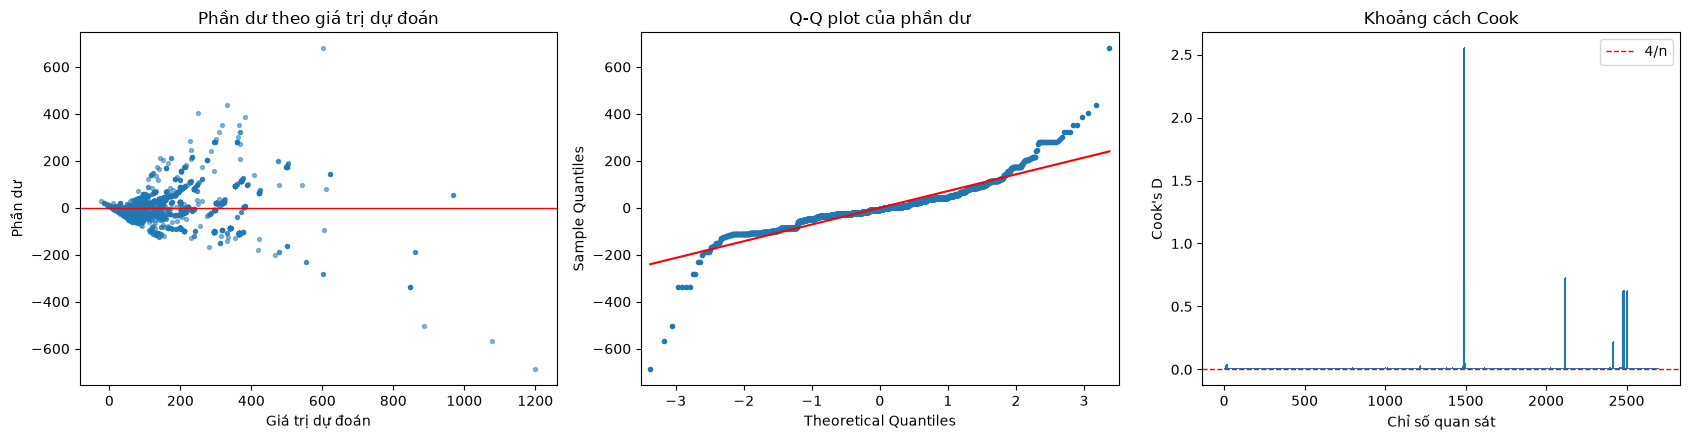

In [29]:
resid  = model.resid
fitted = model.fittedvalues

bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(resid, X)
jb_stat, jb_p, skew, kurt = jarque_bera(resid)
dw = durbin_watson(resid)

diag = pd.DataFrame({
    "Thống kê": [bp_lm, dw, jb_stat],
    "p-value": [bp_p, np.nan, jb_p],
    "Kết luận": [
        "Phương sai thay đổi (vi phạm)" if bp_p < ALPHA else "Chưa bác bỏ phương sai không đổi",
        "DW gần 2 là không tự tương quan (chỉ có ý nghĩa nếu dữ liệu có thứ tự)",
        "Phần dư không chuẩn" if jb_p < ALPHA else "Chưa bác bỏ phần dư chuẩn",
    ],
}, index=["Breusch-Pagan", "Durbin-Watson", "Jarque-Bera"])
display(diag)

cooks = OLSInfluence(model).cooks_distance[0]
cook_thr = 4 / n
print(f"\nSố quan sát có Cook's D > 4/n ({cook_thr:.5f}): {(cooks > cook_thr).sum()}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].scatter(fitted, resid, s=8, alpha=0.5)
ax[0].axhline(0, color="red", lw=1)
ax[0].set(title="Phần dư theo giá trị dự đoán", xlabel="Giá trị dự đoán", ylabel="Phần dư")

sm.qqplot(resid, line="s", ax=ax[1], markersize=3)
ax[1].set_title("Q-Q plot của phần dư")

ax[2].stem(np.arange(n), cooks, markerfmt=",", basefmt=" ")
ax[2].axhline(cook_thr, color="red", ls="--", lw=1, label="4/n")
ax[2].set(title="Khoảng cách Cook", xlabel="Chỉ số quan sát", ylabel="Cook's D")
ax[2].legend()

plt.tight_layout()
plt.show()

## 10. Mã LaTeX cho bảng hệ số

In ra đúng định dạng `captionbelowbox` / `\captable` của báo cáo, số thập phân dùng dấu phẩy. Copy từ output dán vào file `.tex`.

In [30]:
def fmt(v, d=4):
    # dấu phẩy thập phân kiểu Việt Nam; NaN hiển thị "--"
    return "--" if pd.isna(v) else f"{v:.{d}f}".replace(".", ",")

def fmt_p(p):
    return "$<0{,}0001$" if p < 1e-4 else fmt(p, 4)

latex_names = {"const": r"$\beta_0$ (hệ số chặn)",
               "Memory_Bus_Bit": r"$\beta_1$ (\texttt{Memory\_Bus\_Bit})",
               "Memory_Speed_MHz": r"$\beta_2$ (\texttt{Memory\_Speed\_MHz})",
               "Memory_MB": r"$\beta_3$ (\texttt{Memory\_MB})",
               "Process_nm": r"$\beta_4$ (\texttt{Process\_nm})"}

rows = []
for name in ["const"] + FEATURES:
    r = coef_table.loc[name]
    rows.append(
        f"    {latex_names.get(name, name)} & {fmt(r['Hệ số (beta_hat)'], 6)} & "
        f"{fmt(r['Sai số chuẩn'], 6)} & {fmt(r['t'], 3)} & {fmt_p(r['p-value'])} & "
        f"{fmt(r['VIF'], 2)} \\\\"
    )

latex = (
    "\\begin{table}[H]\n"
    "  \\centering\n"
    "  \\begin{captionbelowbox}\\captable{Kết quả ước lượng mô hình hồi quy tuyến tính bội}\\end{captionbelowbox}\n"
    "  \\begin{tabular}{lrrrrr}\n"
    "    \\toprule\n"
    "    Hệ số & $\\hat{\\beta}$ & Sai số chuẩn & $t$ & $p$-value & VIF \\\\\n"
    "    \\midrule\n"
    + "\n".join(rows) + "\n"
    "    \\bottomrule\n"
    "  \\end{tabular}\n"
    "\\end{table}\n"
)
print(latex)

print(f"% n = {n}; R^2 = {fmt(model.rsquared)}; R^2 hiệu chỉnh = {fmt(model.rsquared_adj)}; "
      f"F({int(model.df_model)}, {int(model.df_resid)}) = {fmt(model.fvalue, 2)}; "
      f"p(F) = {model.f_pvalue:.3e}")

\begin{table}[H]
  \centering
  \begin{captionbelowbox}\captable{Kết quả ước lượng mô hình hồi quy tuyến tính bội}\end{captionbelowbox}
  \begin{tabular}{lrrrrr}
    \toprule
    Hệ số & $\hat{\beta}$ & Sai số chuẩn & $t$ & $p$-value & VIF \\
    \midrule
    $\beta_0$ (hệ số chặn) & -108,758322 & 8,981114 & -12,110 & $<0{,}0001$ & -- \\
    $\beta_1$ (\texttt{Memory\_Bus\_Bit}) & 0,187995 & 0,006141 & 30,612 & $<0{,}0001$ & 1,08 \\
    $\beta_2$ (\texttt{Memory\_Speed\_MHz}) & 0,085873 & 0,004772 & 17,995 & $<0{,}0001$ & 1,96 \\
    $\beta_3$ (\texttt{Memory\_MB}) & 0,029517 & 0,000594 & 49,728 & $<0{,}0001$ & 1,48 \\
    $\beta_4$ (\texttt{Process\_nm}) & 0,802968 & 0,118054 & 6,802 & $<0{,}0001$ & 1,83 \\
    \bottomrule
  \end{tabular}
\end{table}

% n = 2698; R^2 = 0,7243; R^2 hiệu chỉnh = 0,7239; F(4, 2693) = 1768,90; p(F) = 0.000e+00
